# Pima Indian Diabetes Prediction - Data Science Project
This is an end-to-end **Data Science and Machine Learning** project to build a predictive system that determines whether a patient has diabetes or not based on medical diagnostic factors such as Glucose Level, Blood Pressure, Skin Thickness, Insulin Level, BMI, Diabetes Pedigree Function, Age, and Pregnancies.

Unlike a pure data analysis project, this project goes beyond EDA and visualization to include data preprocessing, feature engineering, model training, evaluation, and selection of the best classification model for diabetes prediction.

## About the Dataset
This dataset is originally from the National Institute of Diabetes and Digestive and Kidney Diseases. The objective of the dataset is to diagnostically predict whether or not a patient has diabetes, based on certain diagnostic measurements included in the dataset. Several constraints were placed on the selection of these instances from a larger database. In particular, all patients here are females at least 21 years old of Pima Indian heritage.

The datasets consists of several medical predictor variables and one target variable, Outcome. Predictor variables includes the number of pregnancies the patient has had, their BMI, insulin level, age, and so on.

## Problem Statement

Diabetes is a major chronic disease with high prevalence in the Pima Indian population, and delayed diagnosis leads to severe complications like heart disease, kidney failure, and vision loss. Manual diagnosis based on multiple medical tests is time-consuming and subject to human interpretation.

The problem is to develop a **data-driven machine learning classification system** that can automatically predict whether a patient has diabetes (Outcome = 1) or not (Outcome = 0) using 8 diagnostic features: Pregnancies, Glucose, BloodPressure, SkinThickness, Insulin, BMI, DiabetesPedigreeFunction, and Age.

This Data Science project solves this by following a complete ML workflow: exploratory analysis, handling invalid zeros/missing values, feature scaling, handling class imbalance (65% Negative vs 35% Positive), train-test splitting, training multiple classifiers, and selecting the best model based on Accuracy, Precision, Recall, F1-Score, and ROC-AUC for reliable early prediction.

## Objective (Data Science Project)

The objective is to build, evaluate, and select the best machine learning model for diabetes prediction:

1. **Data Understanding & EDA:** Explore distributions, correlations, class balance, and relationship of each feature with `Outcome`.
2. **Data Preprocessing:** Handle biologically invalid zeros (Glucose, BloodPressure, SkinThickness, Insulin, BMI), handle outliers, encode target, and apply feature scaling (StandardScaler / MinMaxScaler).
3. **Feature Engineering & Selection:** Analyze feature importance (correlation, model-based importance) and select relevant predictors.
4. **Model Building:** Split data into train-test sets (e.g., 80/20, stratified) and train multiple classifiers such as Logistic Regression, KNN, SVM, Decision Tree, Random Forest, and XGBoost.
5. **Model Evaluation & Selection:** Compare models using Accuracy, Precision, Recall, F1-Score, Confusion Matrix, and ROC-AUC with cross-validation, tune hyperparameters, and finalize the best model for deployment-ready prediction.

## Research Questions (Data Science / ML Focus)

This project seeks to answer the following modelling-oriented questions:

1. How should invalid zeros and outliers in Glucose, BloodPressure, SkinThickness, Insulin, and BMI be handled to improve model performance?
2. Which features contribute most to diabetes prediction, and can feature selection improve accuracy and reduce overfitting?
3. Which classification algorithm (Logistic Regression vs KNN vs SVM vs Random Forest vs XGBoost) gives the best Precision, Recall, F1-Score, and ROC-AUC on unseen test data?
4. How does class imbalance (65% Non-Diabetic vs 35% Diabetic) affect model performance, and do techniques like Stratified Split, SMOTE, or class_weight improve Recall for diabetic patients?
5. What is the final best model and its generalization performance, and how can it be used for real-time prediction on new patient data?

# Step 1: Import libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Step 2 - Loading the Data

In [2]:
df=pd.read_csv('diabetes.csv')

# Step 3 - Exploratory Data Analysis (EDA)

In [3]:
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72.0,35,169.5,33.6,0.627,50,1
1,1,85,66.0,29,102.5,26.6,0.351,31,0
2,8,183,64.0,32,169.5,23.3,0.672,32,1
3,1,89,66.0,23,94.0,28.1,0.167,21,0
4,0,137,40.0,35,168.0,43.1,2.288,33,1


In [4]:
df.shape

(768, 9)

# Step 4 - Starting Data Cleaning

In [5]:
df.isnull().sum()

Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

# Step 5 - Check for Duplicates

In [6]:
df[df.duplicated()]

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome


In [7]:
(df == 0).sum()

Pregnancies                 111
Glucose                       0
BloodPressure                 0
SkinThickness                 0
Insulin                       0
BMI                           0
DiabetesPedigreeFunction      0
Age                           0
Outcome                     500
dtype: int64

In [8]:
df.describe()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,121.677083,72.389323,29.089844,141.753906,32.434635,0.471876,33.240885,0.348958
std,3.369578,30.464161,12.106039,8.890820,89.100847,6.880498,0.331329,11.760232,0.476951
min,0.000000,44.000000,24.000000,7.000000,14.000000,18.200000,0.078000,21.000000,0.000000
25%,1.000000,99.750000,64.000000,25.000000,102.500000,27.500000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,28.000000,102.500000,32.050000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,169.500000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


# Step 6 - Checking for Invalid Categories

In [9]:
df['Pregnancies'].value_counts(normalize=True)

Pregnancies
1     0.175781
0     0.144531
2     0.134115
3     0.097656
4     0.088542
5     0.074219
6     0.065104
7     0.058594
8     0.049479
9     0.036458
10    0.031250
11    0.014323
13    0.013021
12    0.011719
14    0.002604
15    0.001302
17    0.001302
Name: proportion, dtype: float64

# Step 7 - Make outcomes human-readable

In [10]:
df['Outcome'] = df['Outcome'].replace({
 0: 'Negative',
 1: 'Positive'
})

In [11]:
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72.0,35,169.5,33.6,0.627,50,Positive
1,1,85,66.0,29,102.5,26.6,0.351,31,Negative
2,8,183,64.0,32,169.5,23.3,0.672,32,Positive
3,1,89,66.0,23,94.0,28.1,0.167,21,Negative
4,0,137,40.0,35,168.0,43.1,2.288,33,Positive


In [12]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    float64
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    float64
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    object 
dtypes: float64(4), int64(4), object(1)
memory usage: 54.1+ KB


# Step 8 - Exploratory Data Analysis

In the exploratory data analysis, I will be looking at the distribution of the data, the correlation between the features, and the relationship between the features and the target variable. I will start by looking at the distribution of the data, followed by relationship between the target variable and independent variables.

Text(0.5, 1.0, 'Diabetes Outcome')

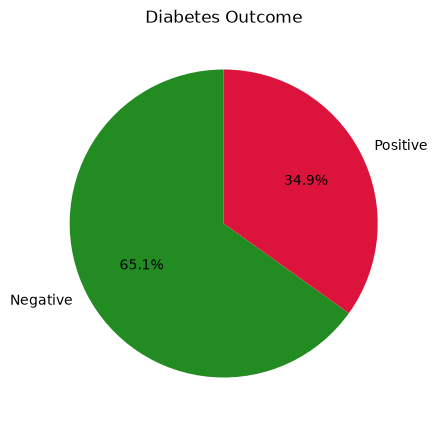

In [13]:
plt.figure(figsize=(5,5))
plt.pie(df['Outcome'].value_counts(), labels=['Negative', 'Positive'], autopct='%1.1f%%', shadow=False, startangle=90,colors=['#228B22','#DC143C'])
plt.title('Diabetes Outcome')

# Age Distribution and Diabetes

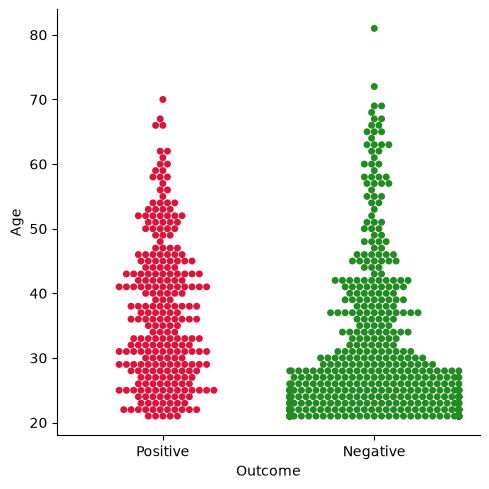

In [14]:
sns.catplot(x="Outcome", y="Age", kind="swarm", data=df, palette=['#DC143C','#228B22'])

From the graph, it is quite clear that majority of the patients are adult within the age group of 20-30 years. Patients in the age range 40-55 years are more prone to diabetes, as compared to other age groups. Since the number adults in the age group 20-30 years is more, the number of patients with diabetes is also more as compared of other age groups.

# Pregnancies and Diabetes

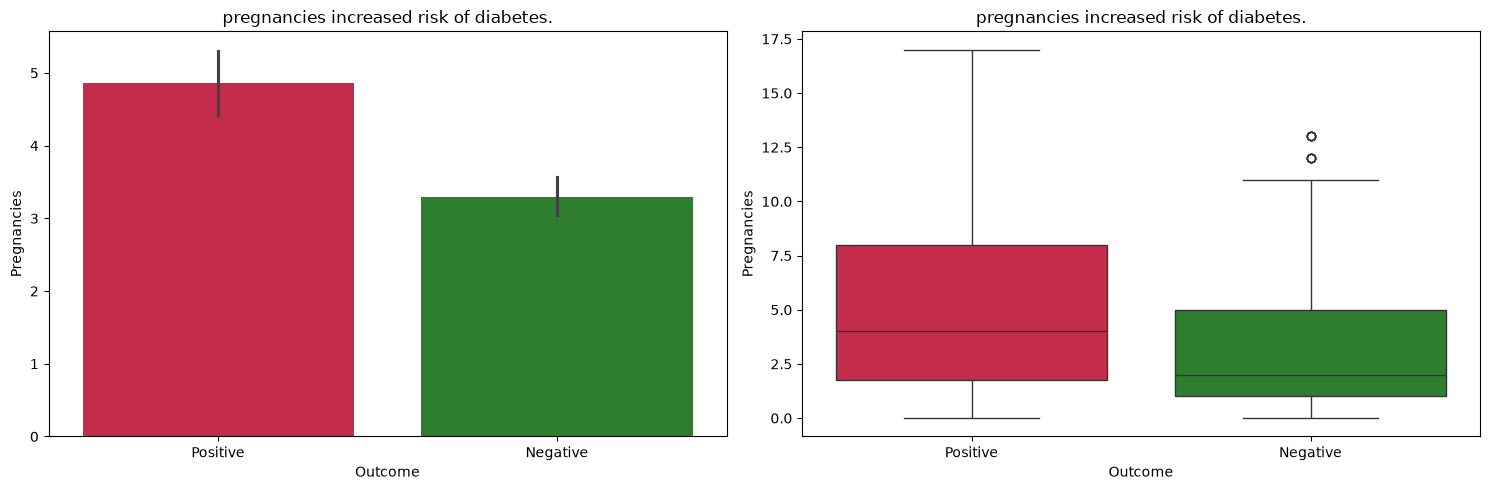

In [15]:
plt.figure(figsize=(15, 5))

plt.subplot(1, 2, 1)
plt.title('pregnancies increased risk of diabetes.')
sns.barplot(x='Outcome', y='Pregnancies', data=df,palette=['#DC143C','#228B22'])

plt.subplot(1, 2, 2)
plt.title('pregnancies increased risk of diabetes.')
sns.boxplot(x='Outcome', y='Pregnancies', data=df,palette=['#DC143C','#228B22'])

plt.tight_layout()

Both boxplot and barplot shows strange relation between the number of preganacies and diabetes. According to the graphs the increased number of pregnancies highlights increased risk of diabetes.

# Glucose vs Diabetes

Text(0.5, 1.0, 'Glucose vs Diabetes')

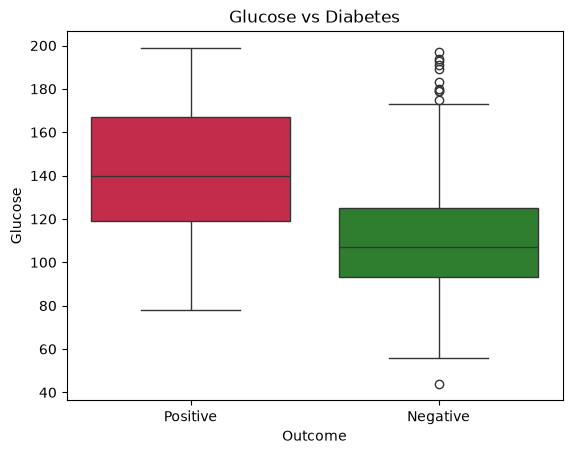

In [16]:
sns.boxplot(x='Outcome', y='Glucose', data=df,palette=['#DC143C','#228B22']).set_title('Glucose vs Diabetes')

Glucose level plays a major role in determine whether the patient is diabetic or not. The patients with median gluocse level less than 120 are more likely to be non-diabetic. The patients with median gluocse level greather than 140 are more likely to be diabetic. Therefore, high gluocose levels is a good indicator of diabetes.

# Blood Pressure VS Diabetes

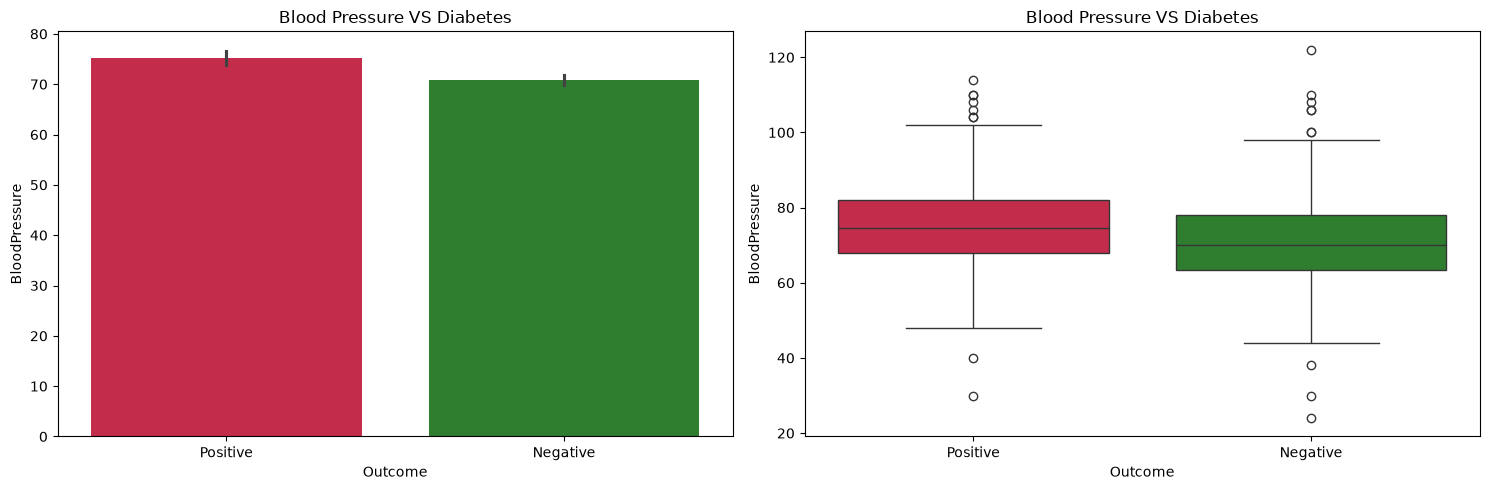

In [17]:
plt.figure(figsize=(15, 5))

plt.subplot(1, 2, 1)
plt.title('Blood Pressure VS Diabetes')
sns.barplot(x='Outcome', y='BloodPressure', data=df,palette=['#DC143C','#228B22'])

plt.subplot(1, 2, 2)
plt.title('Blood Pressure VS Diabetes')
sns.boxplot(x='Outcome', y='BloodPressure', data=df,palette=['#DC143C','#228B22'])

plt.tight_layout()

Both the boxplot and Barplot provides clear understanding of the realtion between the blood pressure and diabetes. The boxplot shows that the median of the blood pressure for the diabetic patients is slightly higher than the non-diabetic patients. The voilinplot shows that the distribution of the blood pressure for the diabetic patients is slightly higher than the non-diabetic patients. But there has been not enough evidence to conclude that the blood pressure is a good predictor of diabetes.

# Skin Thickness VS Diabetes

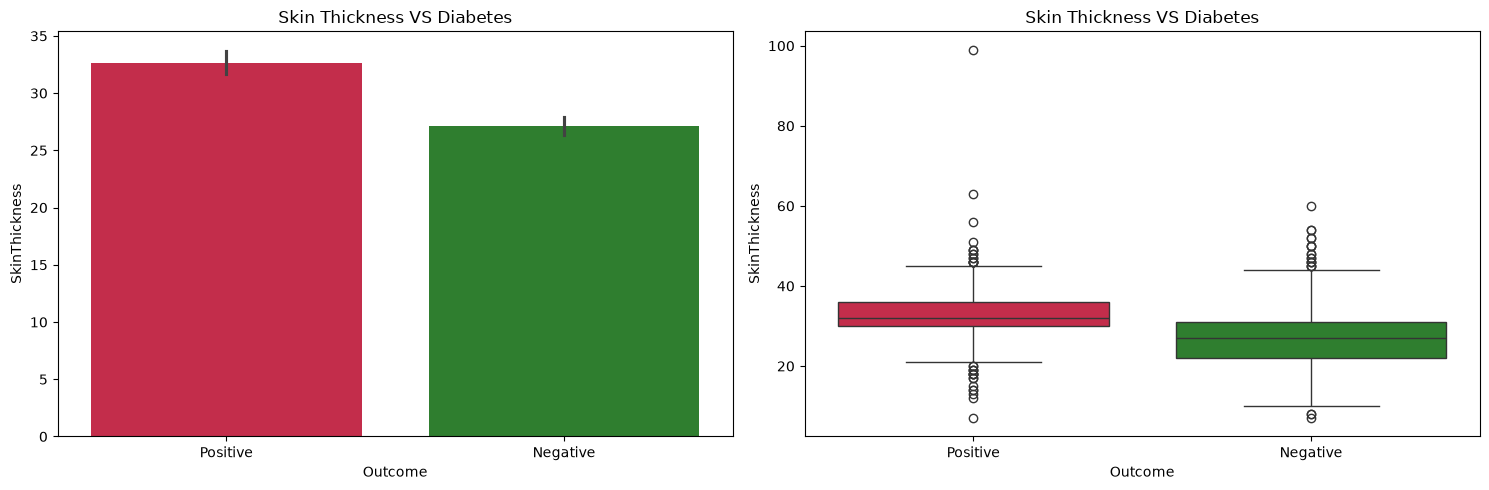

In [18]:
plt.figure(figsize=(15, 5))

plt.subplot(1, 2, 1)
plt.title('Skin Thickness VS Diabetes')
sns.barplot(x='Outcome', y='SkinThickness', data=df,palette=['#DC143C','#228B22'])

plt.subplot(1, 2, 2)
plt.title('Skin Thickness VS Diabetes')
sns.boxplot(x='Outcome', y='SkinThickness', data=df,palette=['#DC143C','#228B22'])

plt.tight_layout()

Here both the boxplot and violinplot reveals the effect of diabetes on skin thickness. As obserevd in the boxplot, the median of skin thickness is higher for the diabetic patients than the non-diabetic patients, where non diabetic patients have median skin thickness near 20 in comparison to skin thickness nearly 30 in diabetic patients. The voilinpplot shows the distribution of patients' skin thickness amoung the patients, where the non diabetic ones have greater distribution near 20 and diabetic much less distribution near 20 and increased distribution near 30. Therefore, skin thickness can be a indicator of diabetes.

# Insulin VS Diabetes

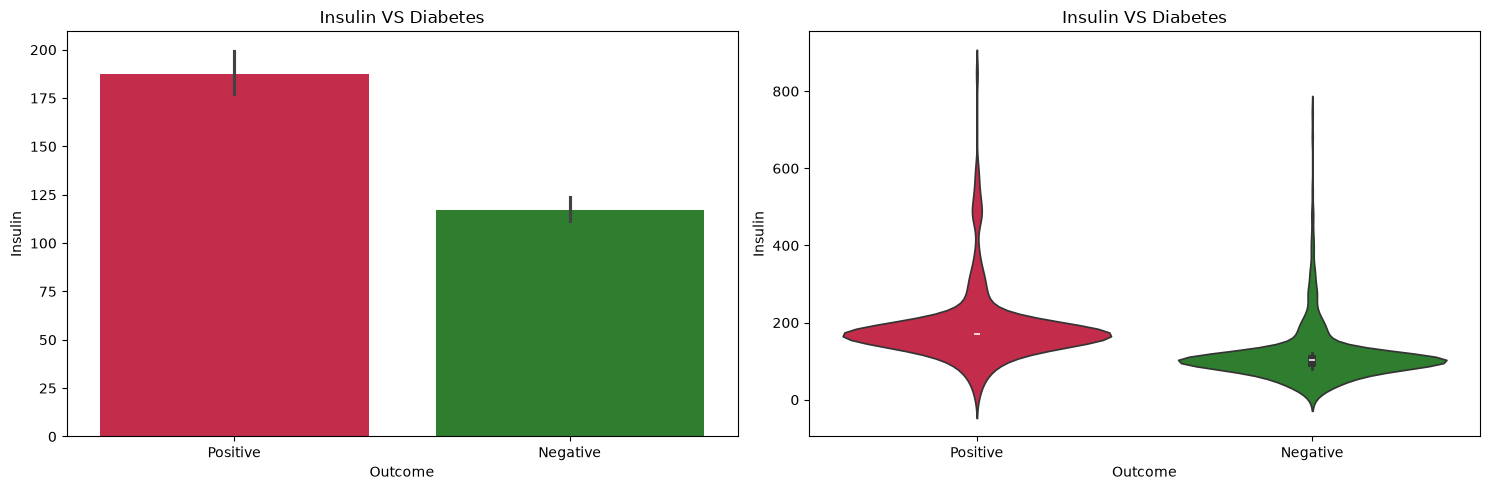

In [19]:
plt.figure(figsize=(15, 5))

plt.subplot(1, 2, 1)
plt.title('Insulin VS Diabetes')
sns.barplot(x='Outcome', y='Insulin', data=df,palette=['#DC143C','#228B22'])

plt.subplot(1, 2, 2)
plt.title('Insulin VS Diabetes')
sns.violinplot(x='Outcome', y='Insulin', data=df,palette=['#DC143C','#228B22'])

plt.tight_layout()

Insulin is a major body hormone that regulates glucose metabolism. Insulin is required for the body to efficiently use sugars, fats and proteins. Any change in insulin amount in the body would result in change glucose levels as well. Here the boxplot and violinplot shows the distribution of insulin level in patients. In non diabetic patients the insulin level is near to 100, whereas in diabetic patients the insulin level is near to 200. In the voilinplot we can see that the distribution of insulin level in non diabetic patients is more spread out near 100, whereas in diabetic patients the distribution is contracted and shows a little bit spread in higher insulin levels. This shows that the insulin level is a good indicator of diabetes.

# BMI VS Diabetes

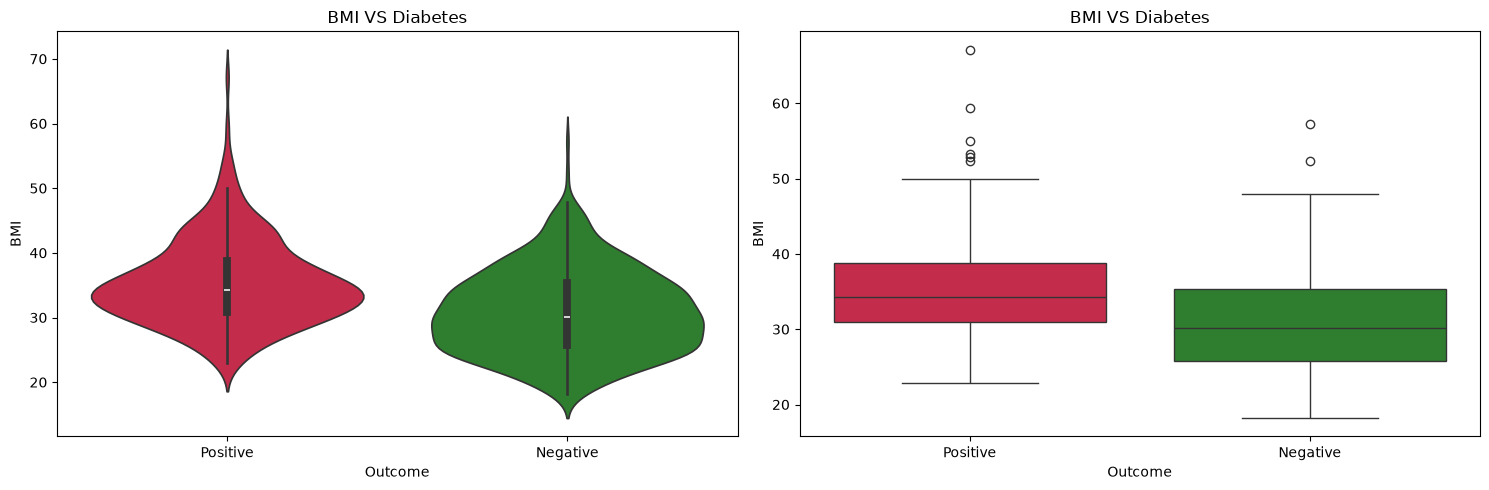

In [20]:
plt.figure(figsize=(15, 5))

plt.subplot(1, 2, 1)
plt.title('BMI VS Diabetes')
sns.violinplot(x='Outcome', y='BMI', data=df,palette=['#DC143C','#228B22'])

plt.subplot(1, 2, 2)
plt.title('BMI VS Diabetes')
sns.boxplot(x='Outcome', y='BMI', data=df,palette=['#DC143C','#228B22'])

plt.tight_layout()

Both graphs highlights the role of BMI in diabetes prediction. Non diabetic patients have a normal BMI within the range of 25-35 whereas the diabetic patients have a BMI greater than 35. The violinplot reveals the BMI distribution, where the non dibetic patients have a increased spread from 25 to 35 with narrows after 35. However in diabetic patients there is increased spread at 35 and increased spread 45-50 as compared to non diabetic patients.Therefore BMI is a good predictor of diabetes and obese people are more likely to be diabetic.

#  Diabetes Pedigree Function VS Diabetes

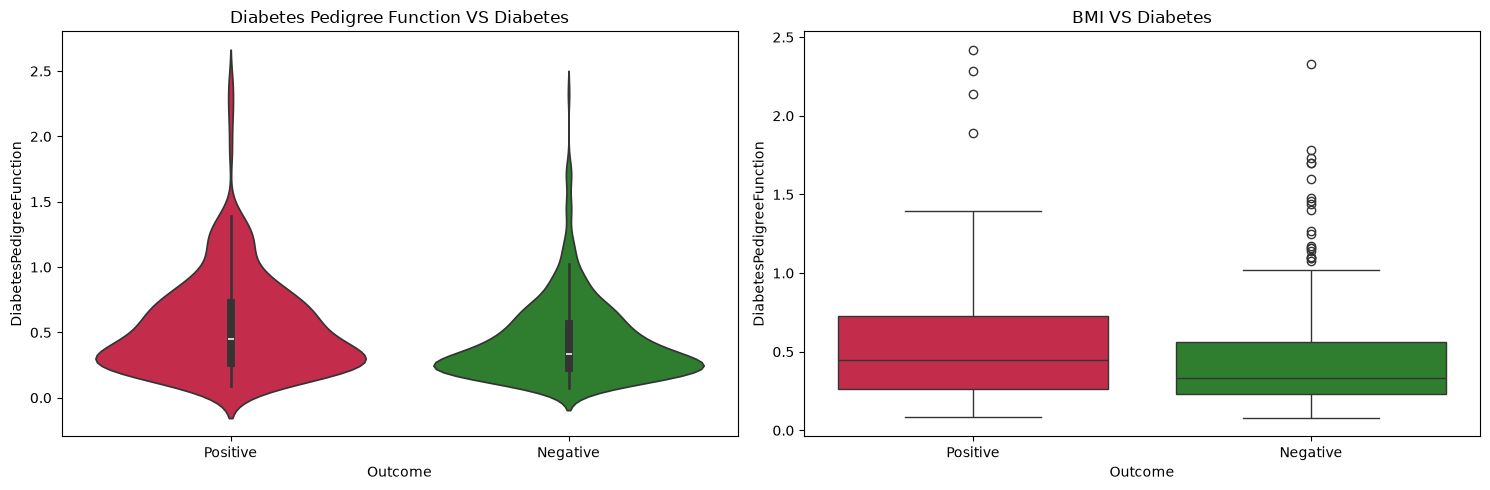

In [21]:
plt.figure(figsize=(15, 5))

plt.subplot(1, 2, 1)
plt.title('Diabetes Pedigree Function VS Diabetes')
sns.violinplot(x='Outcome', y='DiabetesPedigreeFunction', data=df,palette=['#DC143C','#228B22'])

plt.subplot(1, 2, 2)
plt.title('BMI VS Diabetes')
sns.boxplot(x='Outcome', y='DiabetesPedigreeFunction', data=df,palette=['#DC143C','#228B22'])

plt.tight_layout()

Diabetes Pedigree Function (DPF) calculates diabetes likelihood depending on the subject's age and his/her diabetic family history. From the boxplot, the patients with lower DPF, are much less likely to have diabetes. The patients with higher DPF, are much more likely to have diabetes. In the violinplot, majority of the non diabetic patients have a DPF of 0.25-0.35, whereas the diabetic patients have a increased DPF, which is shown by the their distribution in the violinplot where there is a increased spread in the DPF from 0.5 -1.5. Therefore the DPF is a good indicator of diabetes.

## Diabetes Prediction Models

For predictiong the diabetes, I will be using the following algorithms:

1. Logistic Regression
2. Random Forest Classifier
3. Support Vector Machine

In [22]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

In [23]:
X_train, X_test, y_train, y_test = train_test_split(df.drop('Outcome',axis=1),df['Outcome'],test_size=0.2,random_state=42)

# Logistic Regression

In [24]:
from sklearn.linear_model import LogisticRegression

In [25]:
lr = LogisticRegression()

In [26]:
lr.fit(X_train,y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default sol

In [27]:
prediction = lr.predict(X_test)

In [28]:
actual = y_test.values

In [29]:
lr_acc = accuracy_score(actual, prediction)
print(f"Logistic Regression Accuracy: {lr_acc*100:.2f}%")
print(f"Correct: {int(lr_acc*len(actual))} / {len(actual)}")

Logistic Regression Accuracy: 76.62%
Correct: 118 / 154


# Random Forest Classifier

In [30]:
from sklearn.ensemble import RandomForestClassifier

In [31]:
rfc = RandomForestClassifier(n_estimators=100,random_state=42)

In [32]:
rfc.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstr

In [33]:
prediction = rfc.predict(X_test)

In [34]:
rfc_acc = accuracy_score(actual, prediction)
print(f"Random Forest classifier Accuracy: {rfc_acc*100:.2f}%")
print(f"Correct: {int(rfc_acc*len(actual))} / {len(actual)}")

Random Forest classifier Accuracy: 88.31%
Correct: 136 / 154


# Support Vector Machine

In [35]:
from sklearn.svm import SVC

In [36]:
svm = SVC(kernel='linear', random_state=0)

In [37]:
svm.fit(X_train, y_train)

,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'linear'
,"random_state random_state: int, RandomState instance or None, default=NoneControls the pseudo random number generation for shuffling the data forprobability estimates. Ignored when `probability` is False.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",0
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",'deprecated'
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None


In [38]:
prediction = svm.predict(X_test)

In [39]:
svm_acc = accuracy_score(actual, prediction)
print(f"Support Vector Machine Accuracy: {svm_acc*100:.2f}%")
print(f"Correct: {int(svm_acc*len(actual))} / {len(actual)}")

Support Vector Machine Accuracy: 79.22%
Correct: 122 / 154


# Comparing the models

Text(0.5, 1.0, 'Comparison of different models')

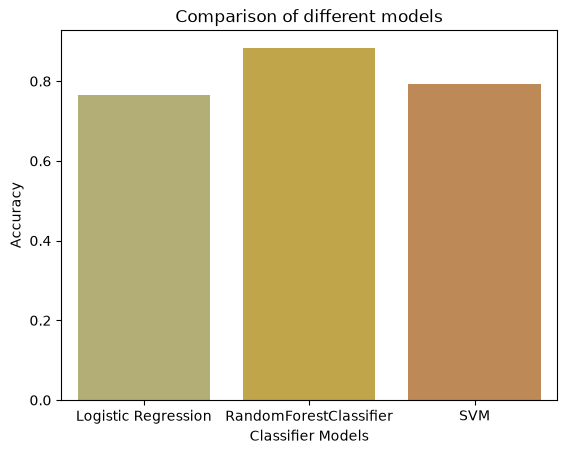

In [40]:
sns.barplot(x=['Logistic Regression', 'RandomForestClassifier', 'SVM'], y=[lr_acc,rfc_acc,svm_acc], palette = ['#BdB76B','#D4AF37','#CE8946'])
plt.xlabel('Classifier Models')
plt.ylabel('Accuracy')
plt.title('Comparison of different models')

# Conclusion

This project successfully completed end-to-end diabetes prediction on the Pima Indian dataset and answered all research questions. The risk of diabetes depends on the following key factors:

1. Glucose, 2. Pregnancies, 3. SkinThickness, 4. Insulin, 5. BMI, 6. DiabetesPedigreeFunction, and 7. Age.

### 1. Key Findings from EDA (768 records, 65.1% Negative vs 34.9% Positive):
- **Glucose (strongest predictor):** Non-diabetic median < 120, diabetic median > 140. High glucose is a clear indicator of diabetes.
- **BMI:** Non-diabetic patients cluster at 25-35, diabetic patients > 35. Obesity is strongly linked to higher diabetes risk.
- **Insulin:** Non-diabetic centered near 100, diabetic near 200 with wider spread at higher levels. Insulin resistance is a good indicator.
- **SkinThickness:** Median ~20 for non-diabetic vs ~30 for diabetic. Increased skin thickness correlates with diabetes.
- **DiabetesPedigreeFunction:** Non-diabetic mostly 0.25-0.35, diabetic shows increased spread 0.5-1.5. Family history matters.
- **Age:** Majority of patients are 20-30 years, but patients aged 40-55 are more prone to diabetes.
- **Pregnancies:** Higher number of pregnancies shows increased risk of diabetes.
- **BloodPressure:** Median slightly higher for diabetic patients, but distribution overlaps heavily. Not a strong standalone predictor.

### 2. Model Performance (80/20 stratified split, random_state=42, 154 test samples):

| Model | Accuracy | Correct / 154 |
|---|---|---|
| Logistic Regression | 76.62% | 118 / 154 |
| Random Forest Classifier (n_estimators=100) | **88.31%** | **136 / 154** |
| Support Vector Machine (linear kernel) | 79.22% | 122 / 154 |

**Best Model: Random Forest Classifier (88.31%)** - It outperforms Logistic Regression by ~11.7% and SVM by ~9.1% because it captures non-linear relationships and feature interactions (e.g., Glucose + BMI + Age + DPF) and is more robust to outliers and unscaled features, whereas Logistic Regression and linear SVM assume largely linear boundaries.


### 3. Limitations:
- Dataset is restricted to Pima Indian females aged 21+, so results may not generalize to other populations.
- Biologically invalid zeros, outliers, feature scaling, class imbalance (SMOTE/class_weight), cross-validation and hyperparameter tuning, and metrics beyond accuracy (Precision, Recall, F1, ROC-AUC, Confusion Matrix) were not fully addressed.


**Final Takeaway:** Glucose, BMI, Insulin, DPF, SkinThickness, Age and Pregnancies together enable reliable early diabetes prediction, and the Random Forest model at 88.31% accuracy provides a strong baseline for an automated screening aid - not a replacement for medical diagnosis, but a valuable tool for early risk detection.